# Detección temprana de daño en el puente Z24 con machine learning

Proyecto de machine learning sobre los datos del monitoreo continuo (EMS) del puente Z24. Se entrena un modelo que predice la frecuencia de cada modo a partir de la temperatura, solo con el puente sano, y se vigila la diferencia entre lo medido y lo predicho para detectar el daño lo antes posible.

Parte de los resultados de los notebooks de la carpeta superior: `results/ems_natural_frequencies.csv` (frecuencias de los modos 1, 2 y 3 en cada medición horaria, de `z24_natural_frequencies_ems.ipynb`) y `cache/ems_inventory.csv` (variables ambientales de cada medición, de `z24_data_structure.ipynb`).

**Índice**
1. [Definición del problema y alcance](#sec1)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Fixed seed, so that any random result is always the same
np.random.seed(42)

# Input files (they are in the parent folder, bridge-z24)
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"

# Important dates
TEST_START = pd.Timestamp("1998-07-15")           # start of the healthy test block
PREP_START = pd.Timestamp("1998-08-05")           # start of the installation of the pier lowering system
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering, -20 mm (Table 8, Appendix F of C11)


# Shows a table with its caption above it
def show_table(table, number, caption):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index"))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Definición del problema y alcance

### 1.1 Problema

- El daño reduce la rigidez del puente y, por lo tanto, sus frecuencias naturales. Vigilar las frecuencias es una forma barata de detectar daño.
- Pero la temperatura también cambia las frecuencias, y en Z24 lo hace en un orden parecido al del daño. Bajo 0 °C el cambio es mayor y no lineal, porque el asfalto y el suelo se congelan y rigidizan el puente.
- Si se compara la frecuencia medida con la de todo el año, el daño queda escondido dentro de la variación por temperatura (Figura 1).

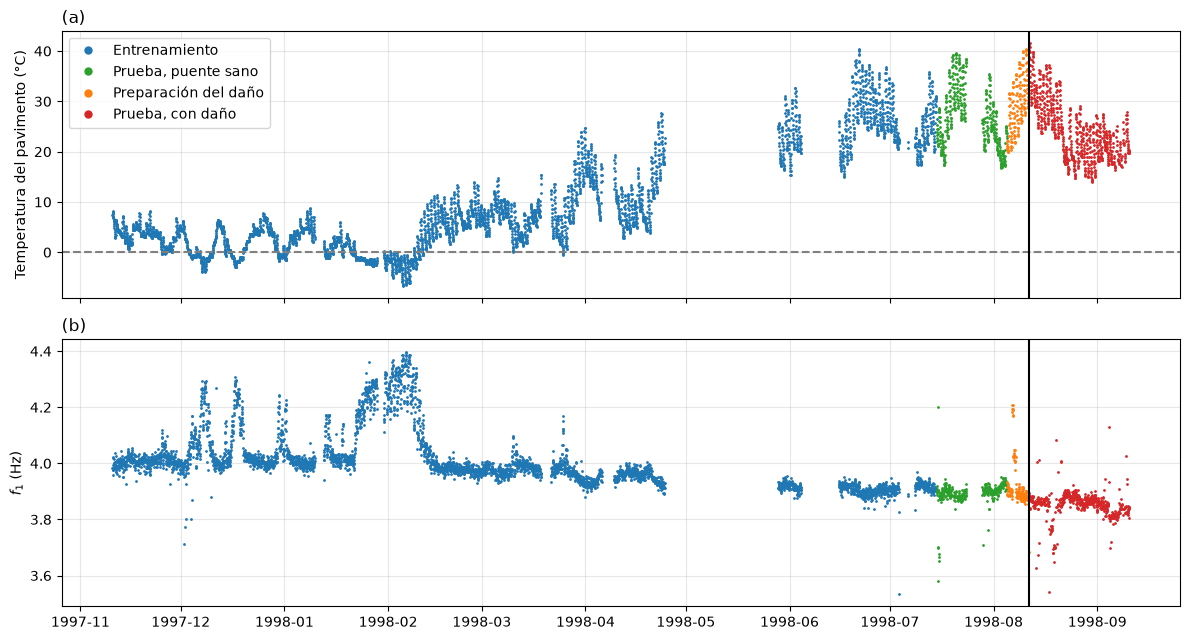

**Figura 1.** Monitoreo del Z24, del 10.11.1997 al 10.09.1998: (a) temperatura del pavimento y (b) frecuencia del modo 1. Los colores son los bloques de tiempo del proyecto (sección 1.5). La línea vertical marca el primer daño (descenso de la pila, 11.08.1998, 13:15) y la discontinua de (a), 0 °C.

In [2]:
# 1. Read the natural frequencies (f1, f2, f3) of each hourly measurement
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])

# 2. Read the two pavement temperature sensors (TP1 and TP2) of each measurement
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code", "TP1", "TP2"])

# 3. Some readings are error codes of the data logger (for example 3276.7).
#    A real temperature is never above 100 °C, so those values are replaced by NaN (empty)
temperatures.loc[temperatures["TP1"].abs() >= 100, "TP1"] = np.nan
temperatures.loc[temperatures["TP2"].abs() >= 100, "TP2"] = np.nan

# 4. Pavement temperature T = average of the two sensors (if one is empty, the other one is used)
temperatures["T"] = temperatures[["TP1", "TP2"]].mean(axis=1)

# 5. Join both tables using the code of the measurement
data = pd.merge(frequencies, temperatures[["code", "T"]], on="code", how="left")


# 6. Assign each measurement to a time block (Section 1.5)
def get_block(date):
    if date < TEST_START:
        return "Entrenamiento"
    elif date < PREP_START:
        return "Prueba, puente sano"
    elif date < DAMAGE_START:
        return "Preparación del daño"
    else:
        return "Prueba, con daño"


data["block"] = data["start"].apply(get_block)

# 7. Plot the temperature and f1 over time, with one color per block
BLOCK_COLORS = {
    "Entrenamiento": "tab:blue",
    "Prueba, puente sano": "tab:green",
    "Preparación del daño": "tab:orange",
    "Prueba, con daño": "tab:red",
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)

for block, color in BLOCK_COLORS.items():
    block_data = data[data["block"] == block]
    axes[0].plot(block_data["start"], block_data["T"], ".", markersize=2, color=color, label=block)
    axes[1].plot(block_data["start"], block_data["f1"], ".", markersize=2, color=color)

# (a) Temperature
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].axvline(DAMAGE_START, color="black")            # first damage
axes[0].set_ylabel("Temperatura del pavimento (°C)")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=5, loc="upper left")
axes[0].grid(alpha=0.3)

# (b) Natural frequency of mode 1
axes[1].axvline(DAMAGE_START, color="black")            # first damage
axes[1].set_ylabel("$f_1$ (Hz)")
axes[1].set_title("(b)", loc="left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Monitoreo del Z24, del 10.11.1997 al 10.09.1998: (a) temperatura del pavimento y (b) "
            "frecuencia del modo 1. Los colores son los bloques de tiempo del proyecto (sección 1.5). La línea "
            "vertical marca el primer daño (descenso de la pila, 11.08.1998, 13:15) y la discontinua de (a), 0 °C.")

- La frecuencia del modo 1 sube en invierno y baja en verano, siguiendo a la temperatura. Los picos más altos coinciden con las heladas.
- Con daño (rojo), $f_1$ baja unos 0.05 Hz respecto al verano sano, mientras que entre invierno y verano la temperatura la mueve más de 0.4 Hz.
- Además, el daño ocurre en la época más caliente, cuando $f_1$ ya es la más baja del año. Sin corregir por temperatura, cuesta separar el efecto del daño del efecto del calor.
- Hay mediciones sueltas muy alejadas de la nube (por ejemplo, bajo 3.7 Hz), que se revisan en la limpieza de datos.

### 1.2 Objetivo

Detectar el daño del Z24 lo antes posible y con pocas falsas alarmas, quitando primero el efecto de la temperatura con un modelo de machine learning.

**Pregunta del proyecto:** con una tasa de falsas alarmas fijada en el puente sano, ¿cuántas horas después del primer daño se detecta?

### 1.3 Enfoque

Es un problema de **detección de novedades** (*novelty detection*): el modelo se entrena solo con el puente sano y aprende lo que es "normal". Las etiquetas de sano y dañado no se usan para entrenar, solo para evaluar.

1. **Modelo de regresión:** predice la frecuencia de cada modo, $\hat{f}_m$, a partir de la temperatura y de las variables que se derivan de ella (sección 1.4).
2. **Residuo:** diferencia entre lo medido y lo predicho,

$$
r_{m,i} = f_{m,i} - \hat{f}_m(\mathbf{x}_i)
\tag{1}
$$

donde $f_{m,i}$ es la frecuencia medida del modo $m$ en la medición $i$, $\mathbf{x}_i$ el vector de variables de entrada de esa medición y $\hat{f}_m(\mathbf{x}_i)$ la frecuencia que predice el modelo. Si el modelo es bueno, en el puente sano el residuo es pequeño y no depende de la temperatura.

3. **Índice de daño:** los residuos de los tres modos se combinan en uno solo con la distancia de Mahalanobis, que tiene en cuenta que los residuos de los modos están correlacionados.
4. **Carta de control:** el índice se suaviza con una media móvil exponencial (EWMA, *Exponentially Weighted Moving Average*), que da más peso a las mediciones recientes:

$$
z_i = \lambda\, d_i + (1 - \lambda)\, z_{i-1}
\tag{2}
$$

donde $d_i$ es el índice de daño de la medición $i$, $z_i$ el valor suavizado y $\lambda \in (0, 1]$ el peso de la medición nueva. Con $\lambda$ pequeño, el ruido de una hora no dispara la alarma, pero un cambio que se mantiene sí. Se comparará también con CUSUM (suma acumulada).

5. **Alarma:** cuando $z_i$ pasa un límite calibrado con los residuos del puente sano que el modelo no vio.

### 1.4 Variables

**Tabla 1.** Variables del modelo.

| Tipo | Variable | Por qué |
|---|---|---|
| Salida | $f_1$, $f_2$, $f_3$ (Hz) | Frecuencias de los tres modos identificados en el EMS |
| Entrada | Temperatura del pavimento, $T$ (°C), promedio de `TP1` y `TP2` | Es la que más se correlaciona con las frecuencias; bajo 0 °C la rigidización viene del asfalto |
| Entrada | Medias móviles de $T$ (6, 12 y 24 h) | El puente tarda en calentarse y enfriarse (inercia térmica) |
| Entrada, variante A | Horas seguidas con $T < 0$ °C | La rigidización depende de cuánto tiempo lleva congelado el puente |
| Entrada, variante B | Grados-hora de helada: suma $-T$ en cada hora bajo 0 °C y resta $T$ en cada hora sobre 0 °C, sin bajar de 0 | Mide también la intensidad de la helada y hace gradual el deshielo |

- Se prueba primero la variante A, después la B y después las dos juntas, y se queda la que dé mejores resultados.
- La humedad, el viento y las otras temperaturas (aire, suelo, cajón) no se usan. La sección 2 muestra con las gráficas de frecuencia frente a temperatura por qué basta con la del pavimento y su historia.

### 1.5 División temporal de los datos

Las mediciones horarias seguidas son casi iguales, así que no se dividen al azar: el test saldría demasiado optimista. Se divide por bloques de tiempo, como si el modelo se entrenara con el pasado y se usara para vigilar el futuro (Tabla 2 y colores de la Figura 1).

In [3]:
# What each block is used for
BLOCK_USE = {
    "Entrenamiento": "Ajuste del modelo; hiperparámetros con validación cruzada por bloques de una semana",
    "Prueba, puente sano": "Calibrar el límite de alarma y medir las falsas alarmas",
    "Preparación del daño": "Se excluye de todo el proyecto: la instalación del sistema para bajar la pila cambió las frecuencias",
    "Prueba, con daño": "Medir el retraso de detección y el porcentaje de horas detectadas",
}

# One row per block: first date, last date and number of measurements
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Desde": block_data["start"].min().strftime("%d.%m.%Y %H:%M"),
        "Hasta": block_data["start"].max().strftime("%d.%m.%Y %H:%M"),
        "Mediciones": len(block_data),
        "Uso": BLOCK_USE[block],
    })
blocks_table = pd.DataFrame(rows)

show_table(blocks_table, 2, "Bloques de tiempo del proyecto.")

**Tabla 2.** Bloques de tiempo del proyecto.

Bloque,Desde,Hasta,Mediciones,Uso
Entrenamiento,10.11.1997 14:00,14.07.1998 23:00,4431,Ajuste del modelo; hiperparámetros con validación cruzada por bloques de una semana
"Prueba, puente sano",15.07.1998 00:00,04.08.1998 23:00,390,Calibrar el límite de alarma y medir las falsas alarmas
Preparación del daño,05.08.1998 00:00,11.08.1998 13:00,158,Se excluye de todo el proyecto: la instalación del sistema para bajar la pila cambió las frecuencias
"Prueba, con daño",11.08.1998 14:00,10.09.1998 13:00,674,Medir el retraso de detección y el porcentaje de horas detectadas


- **Preparación del daño.** Del 05.08.1998 al primer descenso de la pila se instaló el sistema para bajarla: se cortaron tres tramos de la pila Koppigen y se reemplazaron por piezas de acero con gatos hidráulicos (Tabla 2 de `z24_modal_distributions.ipynb`). Eso cambió el puente sano, por ejemplo $f_2$ quedó debajo de la nube del resto del periodo sano. Por eso estas mediciones se excluyen del entrenamiento, de la prueba y de las métricas, como en ese notebook, donde el puente sano es solo lo anterior al 05.08.1998.
- La prueba sana termina el 04.08.1998 y la prueba con daño empieza el 11.08.1998. La carta de control pasa del último dato sano al primero con daño, saltándose la preparación.
- Las heladas quedan todas en el entrenamiento. Las falsas alarmas bajo 0 °C solo se pueden estimar con la validación cruzada.

### 1.6 Métricas

- **Del modelo:** RMSE (*root mean square error*, raíz del error cuadrático medio) de los residuos en la validación cruzada y en la prueba sana, por separado bajo y sobre 0 °C.
- **De la detección:**
  - Tasa de falsas alarmas: porcentaje de horas en alarma en la prueba sana.
  - Retraso de detección: horas desde el primer daño (11.08.1998, 13:15) hasta la primera alarma.
  - Porcentaje de horas en alarma en la prueba con daño.
  - Curva ROC (*Receiver Operating Characteristic*): detecciones frente a falsas alarmas para todos los límites posibles.
- **Comparación:** sin corrección por temperatura, con el modelo bilineal (`z24_modal_distributions.ipynb`) y con los modelos de machine learning, de menos a más complejo (regresión lineal, proceso gaussiano o gradient boosting, red neuronal pequeña).

### 1.7 Fuera del alcance

- La identificación modal desde las aceleraciones: se parte de las frecuencias ya identificadas.
- Localizar o cuantificar el daño: solo se detecta.
- Las formas modales.
- Otros puentes.